# 코드 설명

- **주제** : 악성코드 유형 분포의 월별 변화(개념 변화, concept drift)를 시계열로 보고, 다음 달 비율을 예측하기
- **사용 데이터** : 외부 파일 없음. 월별 유형 분포를 코드 안에 직접 정의
- **사용 라이브러리**
    - `matplotlib` — 유형별 추세 그래프
    - `statsmodels` — 시계열 모형(ARIMA) 적합 및 예측
- **실행 순서** : 월별 분포 정의 → 유형별 시계열로 변환 → 추세 시각화 → 유형별 ARIMA 적합 → 다음 달 예측

> **최신화 메모 (TF1/구버전 → 현재 환경)**
>
> 원본은 `from statsmodels.tsa.arima_model import ARMA` 를 사용했습니다. 이 `arima_model` 모듈과 `ARMA` 클래스는 **statsmodels 0.12에서 제거**되었습니다(현재 0.14+). 현재 환경에서는 통합 API인 `statsmodels.tsa.arima.model.ARIMA` 로 교체합니다.
>
> | 구분 | 원본 (제거됨) | 현재 |
> |---|---|---|
> | import | `tsa.arima_model.ARMA` | `tsa.arima.model.ARIMA` |
> | 차수 지정 | `ARMA(x, order=(0, 1))` | `ARIMA(x, order=(0, 0, 1))` |
> | 적합 | `.fit(disp=True)` | `.fit()` (`disp` 인자 없음) |
> | 예측 | `.predict(n, n)` | `.predict(start=n, end=n)` |
>
> ARMA(p, q) 는 ARIMA(p, **0**, q) 와 같습니다(차분 차수 d=0). 따라서 `ARMA(order=(0, 1))` → `ARIMA(order=(0, 0, 1))` 입니다.

In [1]:
# ── Google Colab 준비 셀 ─────────────────────────────────────────
# 로컬(VS Code, JupyterLab)에서 실행하면 아무 동작 없이 넘어갑니다.
# Colab에서 실행하면 저장소를 내려받아 실습 폴더로 이동합니다.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    저장소 = "https://github.com/isl-hedgehog/python-cyber-seminar.git"
    이름 = 저장소.rsplit("/", 1)[-1].removesuffix(".git")
    실습폴더 = "02-adversarial-malware"

    if not os.path.isdir(f"/content/{이름}"):
        subprocess.run(["git", "clone", "-q", 저장소], cwd="/content", check=True)
    os.chdir(f"/content/{이름}/{실습폴더}")
    # Colab에는 matplotlib, statsmodels가 이미 설치되어 있습니다.
    print("Colab 준비 완료 :", os.getcwd())
else:
    print("로컬 환경 — 준비 셀을 건너뜁니다.")

로컬 환경 — 준비 셀을 건너뜁니다.


### 1. 월별 유형 분포 정의

4개월에 걸친 악성코드 유형별 비율(%)입니다. 각 월은 `{유형: 비율}` 형태의 딕셔너리이며, 네 유형의 합이 100이 되도록 구성되어 있습니다.

In [2]:
month0 = {"Trojan": 24, "CryptoMiner": 11, "Other": 36, "Worm": 29}
month1 = {"Trojan": 28, "CryptoMiner": 25, "Other": 22, "Worm": 25}
month2 = {"Trojan": 18, "CryptoMiner": 36, "Other": 41, "Worm": 5}
month3 = {"CryptoMiner": 18, "Trojan": 33, "Other": 44, "Worm": 5}
months = [month0, month1, month2, month3]

### 2. 유형별 시계열로 변환

월 단위 딕셔너리를 **유형별 시계열 리스트**로 재배열합니다. 모형은 "한 유형의 시간에 따른 값 변화"를 입력으로 받으므로, 유형마다 길이 4짜리 리스트를 만듭니다.

In [3]:
trojan_time_series = []
crypto_miner_time_series = []
worm_time_series = []
other_time_series = []
for month in months:
    trojan_time_series.append(month["Trojan"])
    crypto_miner_time_series.append(month["CryptoMiner"])
    worm_time_series.append(month["Worm"])
    other_time_series.append(month["Other"])

### 3. 추세 시각화

유형별로 4개월 추세를 선 그래프로 그립니다. `savefig` 는 작업 폴더에 PNG 파일로 저장하며(저장소에는 포함하지 않음), `show` 로 화면에 표시합니다.

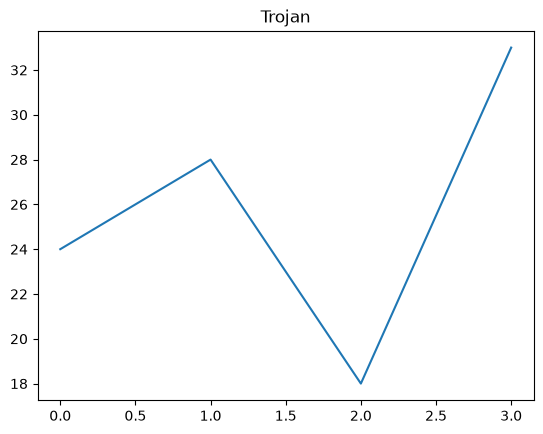

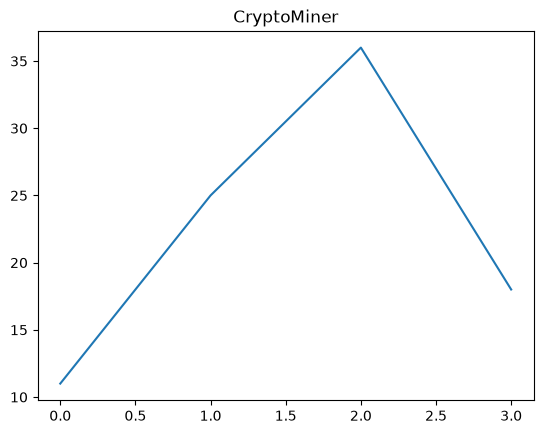

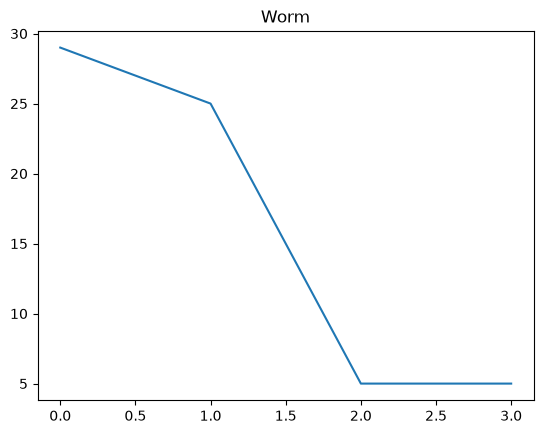

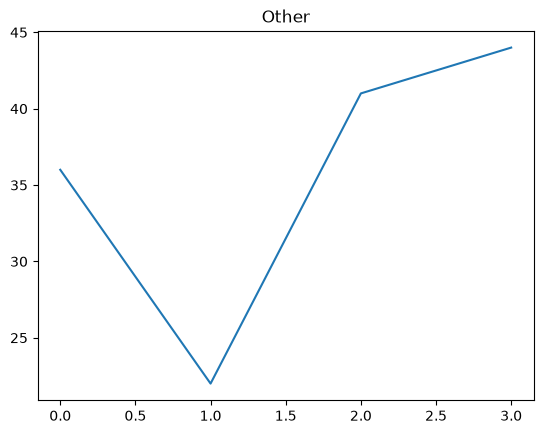

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.title("Trojan")
plt.plot(trojan_time_series)
plt.savefig("TrojanGraph")
plt.show()
plt.title("CryptoMiner")
plt.plot(crypto_miner_time_series)
plt.savefig("CryptoMinerGraph")
plt.show()
plt.title("Worm")
plt.plot(worm_time_series)
plt.savefig("WormGraph")
plt.show()
plt.title("Other")
plt.plot(other_time_series)
plt.savefig("OtherGraph")
plt.show()

### 4. 시계열 모형 준비 — ARIMA

`ARIMA` 를 불러옵니다.

- `ARIMA(x, order=(p, d, q))` — p: 자기회귀 차수, d: 차분 차수, q: 이동평균 차수
- 원본의 `ARMA(x, order=(0, 1))` 은 `ARIMA(x, order=(0, 0, 1))` 과 같습니다.

> 표본이 4개뿐이라 적합 과정에서 `EstimationWarning`(수렴 관련)이 발생합니다. 실습 결과에는 영향이 없으므로, 아래에서는 `warnings.catch_warnings()` 블록으로 fit 구간에서만 경고를 숨깁니다.

In [5]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

### 5. 유형별 다음 달 예측

각 유형의 시계열에 ARIMA(0, 0, 1)을 적합한 뒤, 관측 구간 바로 다음 시점(index = 데이터 길이)을 예측합니다. `predict(start=n, end=n)` 은 길이 n짜리 시계열(index 0..n-1)의 **한 스텝 앞**을 돌려줍니다.

`with warnings.catch_warnings():` 블록은 그 안에서만 경고 설정을 바꾸고 블록을 벗어나면 원래대로 돌려놓습니다. statsmodels가 fit 내부에서 경고 필터를 다시 켜므로, 전역 `filterwarnings` 대신 이 방식으로 감쌉니다.

In [6]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ts_model = ARIMA(trojan_time_series, order=(0, 0, 1))
    model_fit_to_data = ts_model.fit()
y_Trojan = model_fit_to_data.predict(start=len(trojan_time_series), end=len(trojan_time_series))
print("Trojan prediction for following month: " + str(y_Trojan[0]) + "%")

Trojan prediction for following month: 22.400086155311644%


In [7]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ts_model = ARIMA(crypto_miner_time_series, order=(0, 0, 1))
    model_fit_to_data = ts_model.fit()
y_CryptoMiner = model_fit_to_data.predict(start=len(crypto_miner_time_series), end=len(crypto_miner_time_series))
print("CryptoMiner prediction for following month: " + str(y_CryptoMiner[0]) + "%")

CryptoMiner prediction for following month: 24.099935163275497%


In [8]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ts_model = ARIMA(worm_time_series, order=(0, 0, 1))
    model_fit_to_data = ts_model.fit()
y_Worm = model_fit_to_data.predict(start=len(worm_time_series), end=len(worm_time_series))
print("Worm prediction for following month: " + str(y_Worm[0]) + "%")

Worm prediction for following month: 14.998987750945224%


In [9]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ts_model = ARIMA(other_time_series, order=(0, 0, 1))
    model_fit_to_data = ts_model.fit()
y_Other = model_fit_to_data.predict(start=len(other_time_series), end=len(other_time_series))
print("Other prediction for following month: " + str(y_Other[0]) + "%")

Other prediction for following month: 28.89988058276831%
